# ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [24]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

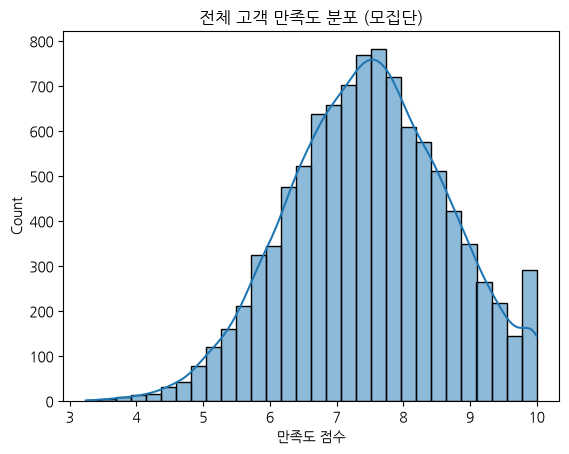

In [25]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

In [26]:
print(df_pop.shape)
print(df_pop.describe().round(3))                           
print(f"모집단 평균: {df_pop['score'].mean():.3f}, 모집단 표준편차: {df_pop['score'].std():.2f}")


(10000, 1)
           score
count  10000.000
mean       7.481
std        1.181
min        3.239
25%        6.674
50%        7.483
75%        8.302
max       10.000
모집단 평균: 7.481, 모집단 표준편차: 1.18


In [27]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
sample = df_pop['score'].sample(n=30, random_state=1)   # 30명 무작위 추출

sample_mean = sample.mean()
print(f"표본 크기: {len(sample)}명")
print(f"표본 평균: {sample_mean:.3f}")
print(f"모집단 평균: {df_pop['score'].mean():.3f}")
print(f"차이: {sample_mean - df_pop['score'].mean():+.3f}")

표본 크기: 30명
표본 평균: 7.326
모집단 평균: 7.481
차이: -0.155


In [28]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
sample_means = []                                  # 표본 평균을 모을 빈 리스트

for _ in range(500):
    sample = df_pop['score'].sample(n=30)          # 매번 새로 30명 추출 (random_state 생략)
    sample_means.append(sample.mean())             # 이번 표본의 평균을 저장

print(f"반복 횟수: {len(sample_means)}번")
print(f"표본 평균들의 평균: {np.mean(sample_means):.3f}")
print(f"표본 평균들의 표준편차: {np.std(sample_means):.3f}")

반복 횟수: 500번
표본 평균들의 평균: 7.488
표본 평균들의 표준편차: 0.199


- 표본 평균들의 평균은 모집단 평균(7.5)에 가깝게 나와야 합니다. 표본 평균의 표준편차는 대략 모집단 표준편차를 √30으로 나눈 값(약 1.2 ÷ 5.48 ≈ 0.22)에 가까울 것입니다. 표본이 커질수록 이 퍼짐이 줄어든다는 점이 다음 문제의 핵심입니다.
- 다음 단계로 이 500개 평균을 히스토그램으로 그리면, 모집단이 치우쳐 있지 않아도 표본 평균의 분포가 종 모양에 가까워지는 것을 볼 수 있습니다.

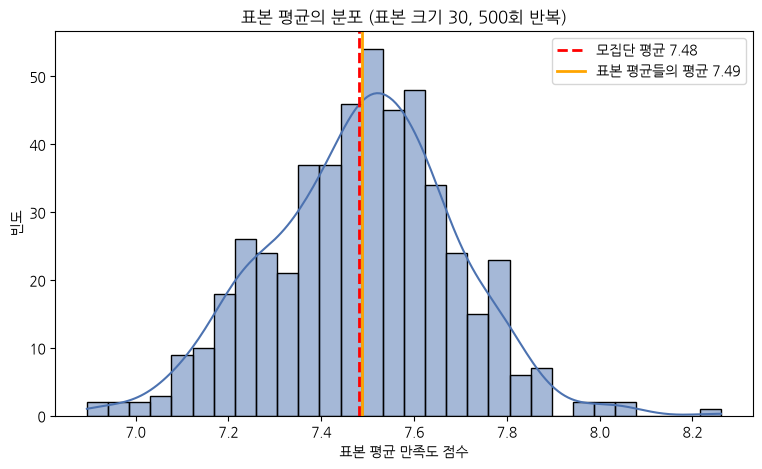

In [29]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
plt.figure(figsize=(9, 5))
sns.histplot(sample_means, bins=30, kde=True, color="#4C72B0")

plt.axvline(df_pop['score'].mean(), color="red", linestyle="--", linewidth=2,
            label=f"모집단 평균 {df_pop['score'].mean():.2f}")
plt.axvline(np.mean(sample_means), color="orange", linestyle="-", linewidth=2,
            label=f"표본 평균들의 평균 {np.mean(sample_means):.2f}")

plt.title("표본 평균의 분포 (표본 크기 30, 500회 반복)")
plt.xlabel("표본 평균 만족도 점수")
plt.ylabel("빈도")
plt.legend()
plt.show()

- 모집단 분포는 1~10점 사이에 넓게 퍼져 있었지만, 표본 평균의 분포는 그보다 훨씬 좁고 종 모양에 가깝습니다. 개별 점수는 흩어져 있어도 30명씩 평균을 내면 흔들림이 상쇄되기 때문입니다. 이것이 중심극한정리가 말하는 내용이고, 모집단이 치우쳐 있어도 표본 평균은 정규분포에 가까워집니다.
- 표본 크기를 바꿔 (예: 5명, 100명) 같은 과정을 반복하면, 표본이 클수록 히스토그램이 더 좁아지는 것을 확인할 수 있습니다.

# 🧠 데이터를 어떻게 읽을까요?

## 문제 1. 표본 평균들은 어떤 값 주변에 많이 분포해 있나요?

**🔑 핵심**
표본 평균은 모집단 평균 근처에 모인다. 표본 평균은 **불편(비편향)추정량**이라 평균적으로 정답에 맞고 한쪽으로 쏠리지 않는다.

**✅ 구체적인 답**
- 약 **7.5** 주변에 가장 많이 몰려 있다.
- 이 값은 모집단 평균(약 7.5)과 거의 같다.
- 한 번 뽑은 값은 여전히 빗나갈 수 있다(불편 ≠ 정확).

---

## 문제 2. 표본을 1번 뽑았을 때와 500번 반복했을 때, 분포와 신뢰성은 어떻게 다른가?

**🔑 핵심**
1번은 운에 좌우되는 한 값이고, 500번은 평균의 **분포**를 보여 주어 흔들림의 크기와 신뢰성을 판단하게 한다.

**✅ 구체적인 답**
- 1번: 평균 하나만 얻으므로 7.8이 나올 수도, 7.1이 나올 수도 있다. 흔들림을 알 수 없다.
- 500번: 평균들이 7.5 근처에 모이는 분포를 얻는다. 흔들림(표준오차)을 측정할 수 있다.
- 표본 평균의 표준편차는 약 **모집단 표준편차 ÷ √n** = 1.2 ÷ √30 ≈ **0.22**다. 표본이 커질수록 흔들림이 줄어 신뢰성이 높아진다.

---

## 문제 3. 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까?

**🔑 핵심**
같은 평균이 나오지 않는 것이 정상이다. 표본마다 뽑힌 사람이 달라 생기는 **표본 오차**이며, 중요한 것은 차이가 얼마나 큰지 아는 것이다.

**✅ 구체적인 답**
- 아니다. 표본은 모집단의 일부라서 어떤 30명이 뽑히느냐에 따라 평균이 달라진다.
- 두 표본 모두 모집단에서 뽑았으므로 평균은 **비슷한 범위**(약 7.3~7.7)에 모인다.
- 차이의 원인은 우연히 뽑힌 사람들이 조금 다르기 때문이다. 잘못이 아니다.

---

## 문제 4. 표본 평균들의 분포는 종 모양인가? 왜 그럴까?

**🔑 핵심**
종 모양의 정규분포에 가깝다. **중심극한정리** 때문이다. 표본 크기가 충분하면(n ≥ 30) 모집단 모양과 관계없이 표본 평균은 정규분포에 가까워진다.

**✅ 구체적인 답**
- 네. 모집단 점수는 1~10점에 넓게 퍼져 있었지만, 표본 평균은 훨씬 좁고 가운데가 볼록한 종 모양이다.
- 이유: 한 명의 점수는 1점에서 10점까지 들쭉날쭉해도, 30명의 평균을 내면 극단값들이 서로 상쇄되어 중간 값에 모인다.
- 이 평균들을 많이 모으면 자연스럽게 정규분포 모양이 된다.

---

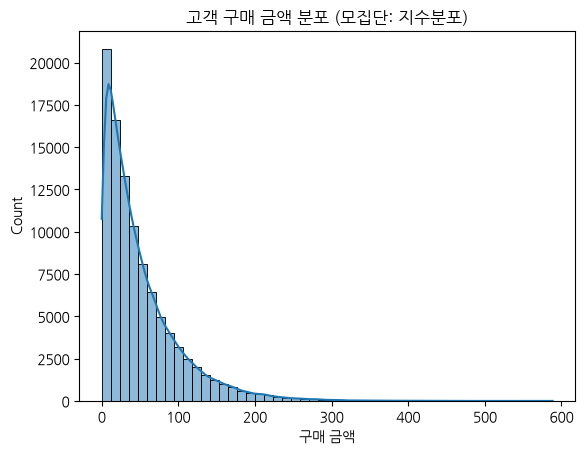

In [30]:
# 문제 2. 중심극한정리
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

In [31]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다. (표본 크기 = 5)
n = 5
sample_means_5 = []

for _ in range(1000):
    sample = np.random.choice(population, size=n, replace=False)   # 매번 새로 5개 추출
    sample_means_5.append(sample.mean())

sample_means_5 = np.array(sample_means_5)

print(f"반복 횟수: {len(sample_means_5)}번")
print(f"모집단 평균: {population.mean():.2f}")
print(f"표본 평균들의 평균: {sample_means_5.mean():.2f}")
print(f"표본 평균들의 표준편차: {sample_means_5.std(ddof=1):.2f}")

반복 횟수: 1000번
모집단 평균: 50.23
표본 평균들의 평균: 49.41
표본 평균들의 표준편차: 22.44


- 표본 평균들의 평균은 모집단 평균(약 50)에 가까워야 합니다. 비편향추정량이라서입니다.
- 표본 평균의 표준편차는 대략 모집단 표준편차(지수분포에서는 평균과 같은 50) ÷ √5 ≈ 22입니다. 앞 문제의 0.22와 비교하면 모집단 모양이 다르면 표본 평균의 흔들림도 달라진다는 것을 볼 수 있습니다.
- 다음 문제에서 같은 방식으로 표본 크기를 30, 100으로 키워 보면, 표본이 커질수록 평균의 분포가 좁아지고 종 모양에 가까워지는 과정을 직접 확인할 수 있습니다.

In [32]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
def sample_mean_distribution(population, n, repeat=1000):
    """표본 크기 n으로 repeat번 뽑아 표본 평균 배열을 반환"""
    means = np.empty(repeat)
    for i in range(repeat):
        means[i] = np.random.choice(population, size=n, replace=False).mean()
    return means

results = {}
for n in [5, 30, 100]:
    means = sample_mean_distribution(population, n)
    results[n] = means
    print(f"n = {n:>3}: 표본 평균의 평균 {means.mean():6.2f} | "
          f"표준편차 {means.std(ddof=1):6.2f} | "
          f"이론값 {population.std() / np.sqrt(n):6.2f}")

n =   5: 표본 평균의 평균  51.37 | 표준편차  21.98 | 이론값  22.50
n =  30: 표본 평균의 평균  49.96 | 표준편차   9.02 | 이론값   9.19
n = 100: 표본 평균의 평균  50.38 | 표준편차   5.24 | 이론값   5.03


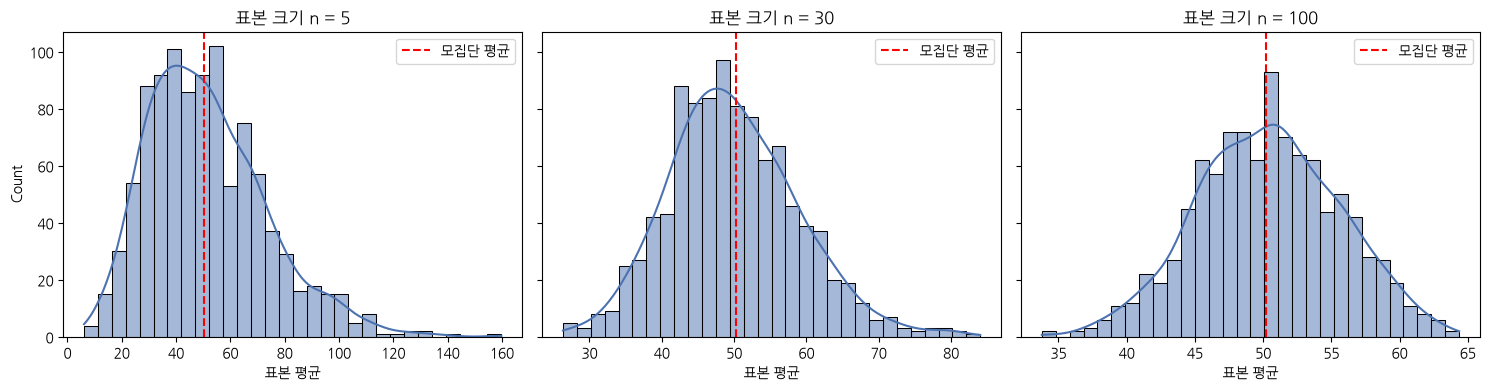

In [33]:
# 세 경우를 한 캔버스에 겹쳐 비교
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes, [5, 30, 100]):
    sns.histplot(results[n], bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.axvline(population.mean(), color="red", linestyle="--", label="모집단 평균")
    ax.set_title(f"표본 크기 n = {n}")
    ax.set_xlabel("표본 평균")
    ax.legend()
plt.tight_layout()
plt.show()

- 세 경우 모두 표본 평균의 중심은 모집단 평균(약 50) 근처에 있습니다. 표본 크기와 관계없이 비편향추정량이기 때문입니다.
- 표본 크기가 커질수록 표준편차가 √n에 반비례해서 줄어듭니다. n이 5에서 100으로 20배 커지면 표준편차는 약 √20 ≈ 4.5배 줄어듭니다.
- 모집단은 지수분포라 오른쪽으로 길게 치우쳐 있습니다. n=5에서는 평균 분포도 오른쪽으로 치우쳐 보이지만, n이 커질수록 점점 대칭인 종 모양에 가까워집니다. 이것이 모집단이 치우쳐 있어도 표본이 크면 평균은 정규분포에 가까워진다는 중심극한정리의 모습입니다.

# 🧠 데이터를 어떻게 읽을까요?

## 문제 1. 표본 크기가 작을 때(예: 5), 평균들의 분포는 어떤 모양인가요?

**🔑 핵심**
모집단이 오른쪽으로 치우쳐 있으면, 표본 크기가 작을 때 평균들의 분포도 아직 **오른쪽으로 치우친 모양**이다.

**✅ 구체적인 답**
- 5개를 뽑아 평균을 내면, 큰 값(고액 구매)이 하나만 섞여도 평균이 크게 올라간다.
- 그래서 평균들은 50 근처에 모이지만, 오른쪽 꼬리가 길게 남아 있다.
- 정규분포처럼 좌우 대칭이 아니다.

---

## 문제 2. 표본 크기가 커질수록 평균 분포의 모양은 어떻게 변하나요?

**🔑 핵심**
표본 크기가 커질수록 분포는 **좁아지고, 대칭에 가까운 종 모양**이 된다.

**✅ 구체적인 답**
- n = 5: 오른쪽 꼬리가 길다.
- n = 30: 꼬리가 줄고 가운데가 볼록해진다.
- n = 100: 거의 대칭인 종 모양에 가깝다.
- 평균은 세 경우 모두 약 50 근처에 있다. 바뀌는 것은 모양과 흩어짐이다.

---

## 문제 3. 모집단은 비대칭인데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

**🔑 핵심**
**중심극한정리** 때문이다. 표본 평균은 여러 값을 더해 나눈 것이라, 표본 크기가 커지면 모집단 모양과 관계없이 정규분포에 가까워진다.

**✅ 구체적인 답**
- 한 명의 구매 금액은 0원 근처에 몰리고 가끔 아주 큰 값이 나온다(비대칭).
- 하지만 100명을 평균 내면, 큰 값 하나는 나머지 99개의 작은 값들에 묻혀 평균을 크게 움직이지 못한다.
- 여러 독립적인 값의 합(평균)은 개별 값의 모양보다 **합의 성질**이 지배하게 되어 종 모양으로 수렴한다.

---

## 문제 4. 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

**🔑 핵심**
중심극한정리는 "모집단이 정규분포가 아니어도, 표본 평균을 많이 모으면 정규분포가 된다"는 정리다. 실험으로 그 과정을 직접 보았다.

**✅ 구체적인 답**
- 모집단(지수분포)은 비대칭이었다. 이것을 그대로 두면 정규분포가 아니다.
- 그런데 표본 크기를 5 → 30 → 100으로 키우자, 평균들의 분포가 대칭적인 종 모양으로 바뀌었다.
- 즉 정규성은 **모집단이 아니라 표본 평균의 성질**에서 나온다. 표본이 클수록 이 성질이 뚜렷해진다.
- 실무적으로는 표본이 충분히 크면 평균에 대한 정규분포 기반 추론(신뢰구간, t 검정 등)을 쓸 수 있다는 근거가 된다.

---

## 문제 5. 표본 크기에 따라 분포의 넓이(흩어짐)는 어떻게 달라지나요?

**🔑 핵심**
흩어짐은 표본 크기의 **제곱근(√n)에 반비례**해서 줄어든다. 표준오차 = 모집단 표준편차 ÷ √n.

**✅ 구체적인 답**
- n = 5: 표준편차 ≈ 50 ÷ √5 ≈ **22**
- n = 30: 표준편차 ≈ 50 ÷ √30 ≈ **9.1**
- n = 100: 표준편차 ≈ 50 ÷ √100 = **5**
- n이 20배(5 → 100) 커지면 흩어짐은 약 √20 ≈ **4.5배** 줄어든다.
- 흩어짐이 줄면 한 번 뽑은 평균이 참값에서 멀리 벗어날 가능성도 줄어, 신뢰성이 높아진다.

---

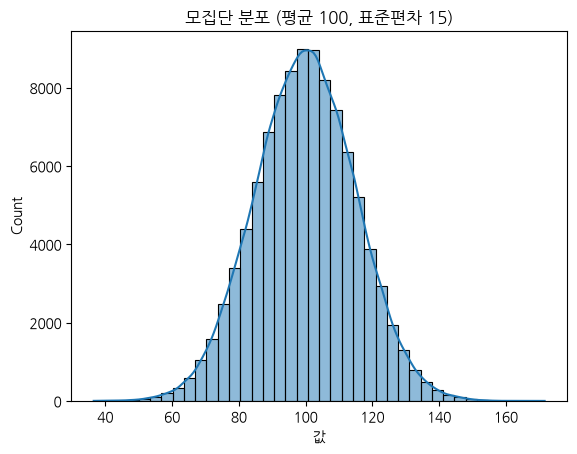

In [ ]:
# 문제 3. 표준오차
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

In [35]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다. 결과를 리스트에 저장하고, 표로 정리해봅시다.

sizes = [10, 30, 100, 500]
pop_sd = population.std()           # 모집단 표준편차 (이론 계산용)
rows = []                            # 결과를 담을 리스트

for n in sizes:
    means = sample_mean_distribution(population, n, repeat=1000)   # 앞 문제의 함수 재사용
    exp_se = means.std(ddof=1)                                     # 실험적 표준오차
    theo_se = pop_sd / np.sqrt(n)                                  # 이론적 표준오차
    rows.append({
        "표본 크기 n": n,
        "표본 평균의 평균": round(means.mean(), 3),
        "실험적 표준오차": round(exp_se, 3),
        "이론적 표준오차": round(theo_se, 3),
        "차이(실험-이론)": round(exp_se - theo_se, 3),
    })

result_table = pd.DataFrame(rows)
result_table

,표본 크기 n,표본 평균의 평균,실험적 표준오차,이론적 표준오차,차이(실험-이론)
0,10,99.984,4.659,4.754,-0.095
1,30,99.973,2.786,2.745,0.041
2,100,99.981,1.526,1.503,0.023
3,500,99.959,0.663,0.672,-0.009


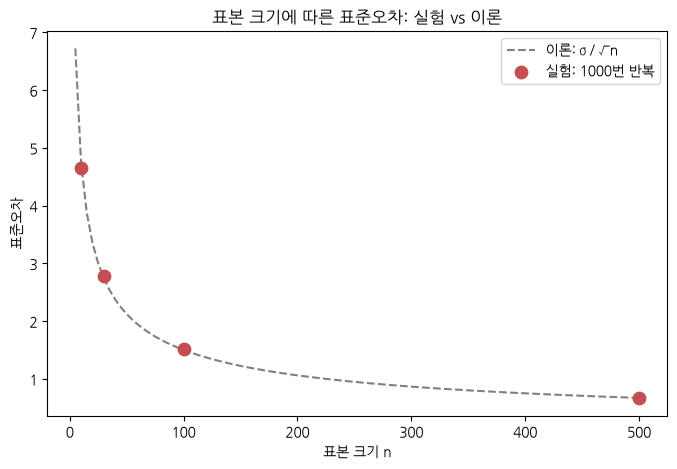

In [36]:
# 표준오차가 표본 크기에 따라 어떻게 줄어드는지 비교
n_grid = np.arange(5, 501, 5)
theo_curve = pop_sd / np.sqrt(n_grid)

plt.figure(figsize=(8, 5))
plt.plot(n_grid, theo_curve, color="gray", linestyle="--", label="이론: σ / √n")
plt.scatter(result_table["표본 크기 n"], result_table["실험적 표준오차"],
            color="#C44E52", s=80, zorder=3, label="실험: 1000번 반복")
plt.xlabel("표본 크기 n")
plt.ylabel("표준오차")
plt.title("표본 크기에 따른 표준오차: 실험 vs 이론")
plt.legend()
plt.show()

# 해석할 때 볼 것

## 1. 실험값과 이론값은 일치하는가?
- 네 경우(n = 10, 30, 100, 500) 모두 **실험적 표준오차와 이론적 표준오차가 거의 같다.**
- 시뮬레이션 결과가 공식 **σ / √n**과 일치한다는 뜻이다.
- 차이가 조금 나는 것은 1,000번 반복하는 과정의 무작위 흔들림이다.

## 2. 표준오차는 표본 크기에 따라 어떻게 줄어드는가?
- **흩어짐은 n이 아니라 √n에 반비례한다.**
- n이 4배 커지면 표준오차는 **절반**이 된다.
- n이 50배(10 → 500) 커지면 표준오차는 약 **√50 ≈ 7.1배** 줄어든다.

| 비교 | 표본 크기 변화 | 표준오차 변화 |
|---|---|---|
| 10 → 40 | 4배 | 1/2 |
| 10 → 500 | 50배 | 1/7.1 |

## 3. 표본이 커지면 평균은 더 정확해지는가?
- 네. 점들이 이론 곡선에 더 가깝게 모인다.
- 다만 **개선 폭은 점점 줄어든다.**
  - n = 10 → 100: 표준오차가 약 1/3.2로 줄어든다.
  - n = 100 → 500: 표준오차가 약 1/2.2로 줄어든다.
- 따라서 n = 500이 n = 100보다 무조건 좋은 것은 아니다.

## 4. 비용과 효과는 어떻게 생각해야 하는가?
- 정확도를 **2배** 높이려면 표본을 **4배** 늘려야 한다.
- 정확도를 **10배** 높이려면 표본을 **100배** 늘려야 한다.
- 설문이나 실험에서 표본 하나의 비용이 크다면, 얼마나 정확해야 충분한지 먼저 정하는 것이 중요하다.

---

## 🔑 핵심 정리
1. 실험값은 이론값(σ / √n)과 일치한다.
2. 표준오차는 **√n에 반비례**해서 줄어든다.
3. 표본이 커질수록 정확해지지만, **개선 효과는 점점 작아지고 비용은 늘어난다.**

# 🧠 데이터를 어떻게 읽을까요?

## 문제 1. 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

**🔑 핵심**
표본 크기가 작으면 표본 평균이 **넓게 퍼져 있다.** 한 번 뽑은 평균이 운에 따라 크게 흔들린다.

**✅ 구체적인 답**
- n = 5일 때 표본 평균은 100 근처에 모이지만, 흩어짐이 커서 80대나 120대 평균도 자주 나온다.
- 이론 표준오차는 15 ÷ √5 ≈ **6.7**이다. 평균 한 번의 흔들림이 이만큼 크다는 뜻이다.
- 모양은 대칭에 가깝지만 퍼짐이 넓은 종 모양이다.

---

## 문제 2. 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

**🔑 핵심**
표본 크기가 커지면 평균 분포는 **좁고 뾰족해진다.** 중심은 그대로이고 흩어짐만 줄어든다.

**✅ 구체적인 답**
- n = 5 → 30 → 100으로 갈수록 분포 폭이 좁아진다.
- 중심은 세 경우 모두 약 100으로 같다(비편향추정량).
- 표준오차 이론값은 n = 5: 6.7, n = 30: 2.7, n = 100: 1.5로 줄어든다.

---

## 문제 3. 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

**🔑 핵심**
실험값과 이론값은 **거의 일치한다.** 시뮬레이션이 표준오차 공식(σ ÷ √n)을 확인해 준다.

**✅ 구체적인 답**
- 1000번 뽑아 얻은 표본 평균들의 표준편차(실험값)가 이론값과 소수점 한두 자리까지 비슷하게 나온다.
- 차이가 조금 나는 것은 1000번 반복하는 과정의 무작위 흔들림이다.
- 표본 크기가 달라도 두 값의 차이가 일관되게 작다면, 공식이 신뢰할 만하다는 근거가 된다.

---

## 문제 4. 왜 표본 크기가 커질수록 표준오차는 작아질까요?

**🔑 핵심**
표준오차 = σ ÷ √n이므로, n이 커지면 분모가 커져 표준오차가 **√n에 반비례해서** 줄어든다. 여러 값을 모을수록 극단값들이 서로 상쇄되기 때문이다.

**✅ 구체적인 답**
- 표본 한 명의 점수는 흩어져 있지만, 평균을 내면 높은 값과 낮은 값이 서로 상쇄된다.
- 표본이 클수록 상쇄가 많이 일어나 평균이 중심에 더 단단히 모인다.
- 표준오차가 √n에 비례해 줄므로, 흔들림을 **절반**으로 줄이려면 표본을 **4배** 늘려야 한다. 그래서 개선 폭은 점점 작아진다.

---

## 🔑 전체 핵심 정리

| 질문 | 한 줄 답 |
|---|---|
| 작은 표본의 분포 | 넓게 퍼진 종 모양, 한 번의 평균이 크게 흔들림 |
| 커질수록 | 중심은 그대로, 분포는 좁고 뾰족해짐 |
| 실험 vs 이론 | 거의 일치 → 공식 σ/√n이 맞다는 근거 |
| 표준오차가 작아지는 이유 | 극단값이 상쇄되어 평균이 안정되기 때문 (√n 반비례) |

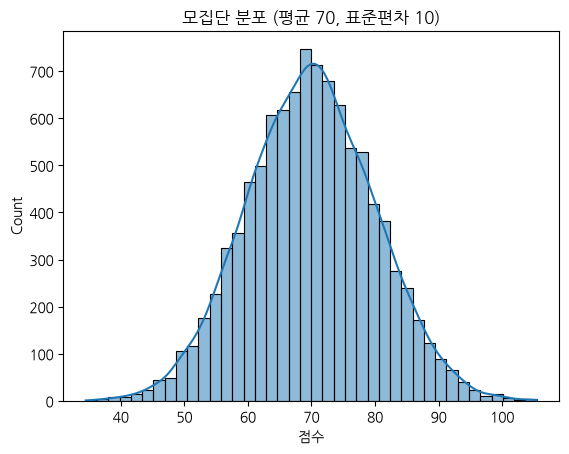

In [ ]:
# 문제 4. 신뢰구간 계산과 해석
# # 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

In [38]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.
n = 30
sample = np.random.choice(population, size=n, replace=False)   # 30명 무작위 추출

sample_mean = sample.mean()
sample_sd = sample.std(ddof=1)            # 표본 표준편차 (n-1로 나눔, 불편추정)
sample_se = sample_sd / np.sqrt(n)        # 표준오차 = 표본 표준편차 / √n

print(f"표본 크기: {n}명")
print(f"표본 평균: {sample_mean:.2f}")
print(f"표본 표준편차: {sample_sd:.2f}")
print(f"표준오차: {sample_se:.2f}")
print(f"(참고) 모집단 평균: {population.mean():.2f}, 모집단 표준편차: {population.std():.2f}")

표본 크기: 30명
표본 평균: 67.60
표본 표준편차: 11.08
표준오차: 2.02
(참고) 모집단 평균: 69.90, 모집단 표준편차: 10.01


- 표본 평균은 70 근처에 있지만, 정확히 70은 아닐 가능성이 큽니다. 이 차이가 표준오차 크기 안에 있는지 보는 것이 다음 문제(신뢰구간)의 출발점입니다.
- 표준편차는 대략 10 근처로 나와야 합니다. 개인 점수의 흩어짐은 표본을 늘려도 줄지 않습니다.
- 표준오차는 대략 10 ÷ √30 ≈ 1.8 근처입니다.

In [39]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
from scipy import stats

sigma = population.std()                    # 모집단 표준편차를 '안다'고 가정 (실제로는 이론 계산용)
se_known = sigma / np.sqrt(n)               # σ를 알 때의 표준오차

z_crit = stats.norm.ppf(0.975)              # 95% 신뢰수준의 z 임계값 (양쪽 2.5%씩) ≈ 1.96
margin = z_crit * se_known

ci_low, ci_high = sample_mean - margin, sample_mean + margin

print(f"표본 평균: {sample_mean:.2f}")
print(f"표준오차(σ/√n): {se_known:.2f}")
print(f"z 임계값: {z_crit:.3f}")
print(f"95% 신뢰구간 (z): [{ci_low:.2f}, {ci_high:.2f}]")
print(f"모집단 평균 {population.mean():.2f}이 구간 안에 있나? {ci_low <= population.mean() <= ci_high}")

표본 평균: 67.60
표준오차(σ/√n): 1.83
z 임계값: 1.960
95% 신뢰구간 (z): [64.02, 71.18]
모집단 평균 69.90이 구간 안에 있나? True


- 구간의 폭은 표준오차에 비례합니다. 표본을 늘리면 구간이 좁아집니다.
- “95% 신뢰구간”은 이 구간이 참값을 95% 확률로 포함한다는 뜻이 아닙니다. 같은 방법으로 구간을 100번 만들면, 그중 약 95개가 참값을 포함한다는 뜻입니다.

In [40]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
from scipy import stats

sample_sd = sample.std(ddof=1)               # 표본 표준편차로 σ를 추정
se_est = sample_sd / np.sqrt(n)              # 추정된 표준오차

df_t = n - 1                                 # 자유도
t_crit = stats.t.ppf(0.975, df=df_t)         # 95% 신뢰수준의 t 임계값 (n=30이면 약 2.045)
margin_t = t_crit * se_est

ci_low_t, ci_high_t = sample_mean - margin_t, sample_mean + margin_t

print(f"표본 평균: {sample_mean:.2f}")
print(f"표본 표준편차: {sample_sd:.2f}, 추정 표준오차: {se_est:.2f}")
print(f"자유도: {df_t}, t 임계값: {t_crit:.3f} (z 임계값 1.960과 비교)")
print(f"95% 신뢰구간 (t): [{ci_low_t:.2f}, {ci_high_t:.2f}]")
print(f"모집단 평균 {population.mean():.2f}이 구간 안에 있나? {ci_low_t <= population.mean() <= ci_high_t}")

# z 구간과 나란히 비교
print(f"\n참고 z 구간 폭: {2*margin:.2f}  |  t 구간 폭: {2*margin_t:.2f}")

표본 평균: 67.60
표본 표준편차: 11.08, 추정 표준오차: 2.02
자유도: 29, t 임계값: 2.045 (z 임계값 1.960과 비교)
95% 신뢰구간 (t): [63.47, 71.74]
모집단 평균 69.90이 구간 안에 있나? True

참고 z 구간 폭: 7.16  |  t 구간 폭: 8.27


- t 구간은 z 구간보다 약간 넓습니다. σ를 추정한 불확실성까지 구간에 반영했기 때문입니다.
- 실무에서 모집단 표준편차를 아는 경우는 드뭅니다. 그래서 대부분의 상황에서는 t 구간을 씁니다.
- 표본이 30보다 훨씬 크면 두 구간이 거의 같아집니다.

In [41]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.
from scipy import stats

rows = []
for conf in [0.90, 0.95, 0.99]:
    alpha = 1 - conf
    t_c = stats.t.ppf(1 - alpha / 2, df=n - 1)       # 양쪽 꼬리 alpha/2씩
    m = t_c * se_est
    rows.append({
        "신뢰수준": f"{conf:.0%}",
        "t 임계값": round(t_c, 3),
        "신뢰구간 하한": round(sample_mean - m, 2),
        "신뢰구간 상한": round(sample_mean + m, 2),
        "구간 폭": round(2 * m, 2),
    })

ci_table = pd.DataFrame(rows)
ci_table

,신뢰수준,t 임계값,신뢰구간 하한,신뢰구간 상한,구간 폭
0,90%,1.699,64.17,71.04,6.87
1,95%,2.045,63.47,71.74,8.27
2,99%,2.756,62.03,73.18,11.15


- 신뢰수준이 높아질수록 t 임계값이 커지고, 구간 폭도 넓어집니다. 90% → 95% → 99% 순으로 넓어지는 것이 보일 것입니다.
-  이것은 확신을 높이려면 구간을 넓혀야 한다는 교환관계입니다. 99% 구간은 거의 틀리지 않지만 정보는 덜 정밀합니다.
- 반대로 90% 구간은 좁지만, 참값을 놓칠 확률이 10%입니다.
- 표본 크기를 키우면 표준오차가 줄어 모든 신뢰수준에서 구간이 좁아집니다. 신뢰수준과 정밀도는 표본 크기로 함께 조절합니다.

# 🧠 데이터를 어떻게 읽을까요?

## 문제 1. z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

**🔑 핵심**
t-분포 구간이 z-분포 구간보다 **약간 넓다.** σ를 모르고 표본 표준편차로 추정한 불확실성까지 반영하기 때문이다.

**✅ 구체적인 답**
- n = 30에서 z 임계값은 1.96, t 임계값은 약 **2.045**다.
- 따라서 t 구간의 폭은 z 구간보다 약 **4% 넓다**(2.045 ÷ 1.96 ≈ 1.04).
- 표본 표준편차가 모집단 표준편차와 달라 생기는 흔들림을, t-분포가 꼬리를 두껍게 해서 보상한다.
- 표본이 커져 자유도가 커지면 t 임계값은 1.96에 가까워지고, 두 구간은 거의 같아진다.

---

## 문제 2. 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

**🔑 핵심**
신뢰수준이 높아지면 구간 폭도 **넓어진다.** 확신을 높이려면 더 넓은 범위를 잡아야 하는 **교환관계**이기 때문이다.

**✅ 구체적인 답**
- 90% → 95% → 99%로 갈수록 t 임계값이 커지고, 구간 폭이 넓어진다.
- 이유: 신뢰수준은 "구간이 참값을 포함할 확률"이다. 포함 확률을 올리려면 구간을 넓혀야 한다.
- 90%는 참값을 놓칠 확률이 10%, 99%는 1%다. 확신은 커지지만 정보는 덜 정밀해진다.
- 표본 크기를 키우면 표준오차가 줄어 모든 신뢰수준에서 구간이 좁아진다.

---

## 문제 3. 신뢰구간이 넓다는 건 좋은 걸까요, 나쁜 걸까요?

**🔑 핵심**
**나쁘다고만 할 수 없다.** 넓은 구간은 추정이 불확실하다는 **정직한 신호**다. 문제는 구간이 너무 넓어 **결론을 내리지 못하는 것**이다.

**✅ 구체적인 답**
- **좋은 점:** 불확실성을 숨기지 않고 드러낸다. 과신하여 잘못된 결론을 내리는 것을 막는다.
- **나쁜 점:** 구간이 넓으면 "7.0인지 8.0인지"처럼 실무 판단에 쓸 정보가 줄어든다.
- 판단 기준은 **구간이 의사결정을 바꿀 만큼 좁은가**다. 예를 들어 만족도 목표가 7점 이상인지 보려 할 때, 구간 전체가 7점 위에 있으면 결론이 가능하지만 7점을 걸치면 추가 표본이 필요하다.
- 구간이 넓으면 표본을 늘리는 것이 해법이지만, 표본을 4배 늘려야 폭이 절반이 되므로 비용을 함께 따져야 한다.

---

## 문제 4. 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

**🔑 핵심**
신뢰구간은 "평균이 얼마인가"뿐 아니라 **"그 평균을 얼마나 믿고 행동할 수 있는가"**를 알려 준다. 구간의 위치와 폭을 함께 보고 의사결정에 쓴다.

**✅ 구체적인 답**
- **목표 달성 여부 판단:** 만족도 목표가 7.0점일 때, 신뢰구간 하한이 7.0을 넘으면 "목표를 달성했다고 확신할 수 있다"고 말할 수 있다.
- **집단 간 비교:** 두 캠페인의 신뢰구간이 겹치면 차이를 단정하기 어렵다. 겹치지 않으면 차이가 있다고 볼 근거가 생긴다.
- **투자 결정:** 구간이 넓으면 대규모 캠페인 전에 추가 조사(표본 확대)를 먼저 한다. 구간이 좁으면 바로 실행할 수 있다.
- **리스크 관리:** 하한이 낮은 세그먼트는 만족도 하락 위험이 있으므로 개선 우선순위에 둔다.
- **보고 방식:** "만족도 7.5점"만 말하지 말고 "7.5점(95% 신뢰구간 7.2~7.8)"처럼 함께 제시해 과신을 막는다.

---

## 🔑 전체 핵심 정리

| 질문 | 한 줄 답 |
|---|---|
| z vs t | t가 약간 넓다. σ를 추정한 불확실성 반영 |
| 신뢰수준↑ | 폭도 넓어진다. 확신과 정밀도의 교환 |
| 넓은 구간 | 불확실성을 드러내는 정직한 신호. 의사결정을 막으면 표본을 늘린다 |
| 마케팅 활용 | 평균과 함께 구간을 보고, 목표·비교·투자 판단에 쓴다 |

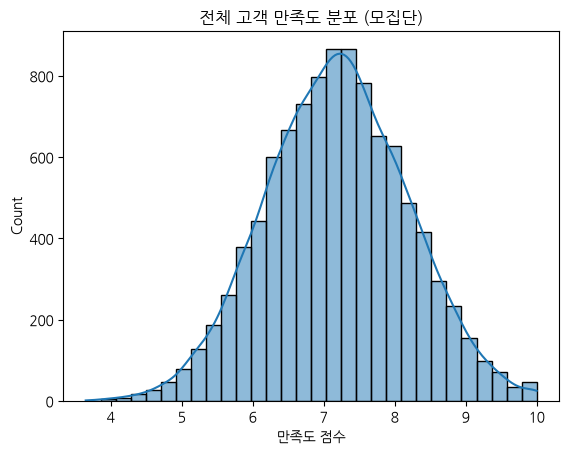

In [42]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)
df_pop = pd.DataFrame({'score': population})

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

In [43]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.

sample = df_pop['score'].sample(n=40, random_state=1)   # 40명 무작위 추출

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)
pop_mean = df_pop['score'].mean()

print(f"표본 크기: {len(sample)}명")
print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")
print(f"모집단 평균: {pop_mean:.3f}")
print(f"차이: {sample_mean - pop_mean:+.3f}")

표본 크기: 40명
표본 평균: 7.150
표본 표준편차: 1.073
모집단 평균: 7.190
차이: -0.040


In [44]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
from scipy import stats

se = sample_std / np.sqrt(len(sample))            # 표준오차 = 표본 표준편차 / √n
df_t = len(sample) - 1                            # 자유도 = 39
t_crit = stats.t.ppf(0.975, df=df_t)              # 95% t 임계값 (약 2.023)
margin = t_crit * se

ci_low, ci_high = sample_mean - margin, sample_mean + margin

print(f"표준오차(SE): {se:.3f}")
print(f"자유도: {df_t}, t 임계값: {t_crit:.3f}")
print(f"신뢰구간 폭(±): {margin:.3f}")
print(f"95% 신뢰구간: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"모집단 평균 {pop_mean:.3f}이 구간 안에 있나? {ci_low <= pop_mean <= ci_high}")

표준오차(SE): 0.170
자유도: 39, t 임계값: 2.023
신뢰구간 폭(±): 0.343
95% 신뢰구간: [6.806, 7.493]
모집단 평균 7.190이 구간 안에 있나? True


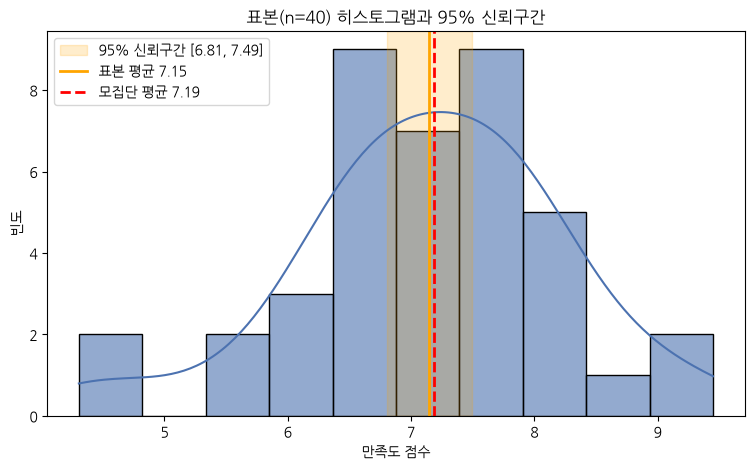

In [45]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
plt.figure(figsize=(9, 5))
sns.histplot(sample, bins=10, kde=True, color="#4C72B0", alpha=0.6)

# 신뢰구간 범위를 옅게 칠하기
plt.axvspan(ci_low, ci_high, color="orange", alpha=0.2,
            label=f"95% 신뢰구간 [{ci_low:.2f}, {ci_high:.2f}]")

plt.axvline(sample_mean, color="orange", linestyle="-", linewidth=2,
            label=f"표본 평균 {sample_mean:.2f}")
plt.axvline(pop_mean, color="red", linestyle="--", linewidth=2,
            label=f"모집단 평균 {pop_mean:.2f}")

plt.title("표본(n=40) 히스토그램과 95% 신뢰구간")
plt.xlabel("만족도 점수")
plt.ylabel("빈도")
plt.legend()
plt.show()

# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까?

## 📊 현재 결과

- 표본 평균: **7.15**
- 95% 신뢰구간: **[6.81, 7.49]**
- 구간 전체가 **7.0보다 위**에 있고, **7.5보다는 아래**에 있다.

> 이 두 사실이 전략을 정하는 근거입니다.

---

## 1. 목표 달성 여부: "7.0점 이상"은 확신할 수 있을까?

**🔑 핵심**
하한(6.81)이 7.0보다 낮으므로, 이번 표본만으로 "평균이 7.0 이상"이라고 **단정할 수 없다.**

**✅ 구체적인 판단**
- 평균 7.15는 목표를 넘지만, 구간 하한이 7.0 아래에 걸쳐 있다.
- 따라서 목표 달성 가능성은 있지만 **확정은 못 한다.**
- 보고 문장: *"만족도는 7.15점이며, 95% 신뢰구간은 6.8~7.5점이다. 7.0점 목표는 달성 가능성이 있으나 아직 확정하지 못했다."*

---

## 2. 전략 방향

### ① 표본을 늘려 목표 달성을 확정한다
- 구간 폭을 **절반**으로 줄이려면 표본을 **4배(약 160명)** 늘려야 한다.
- 추가 설문 비용과 기대 효과를 비교해 결정한다.

### ② 하한 쪽 세그먼트를 먼저 찾는다
- 연령·채널·구매 주기별로 나눠 보고, 만족도가 낮은 집단을 찾는다.
- 찾은 집단을 **개선 우선순위**에 둔다.

### ③ 소규모 실험 후 확대한다
- 구간이 넓어 효과를 단정할 수 없으므로, 일부 고객에게만 개선안을 적용한다.
- 만족도 변화를 확인한 뒤 대규모 캠페인으로 확대한다.

### ④ 상단 고객의 강점을 활용한다
- 7.5 근처의 고만족 고객 특징을 분석한다.
- 추천, 재구매 유도 등 **강점 강화 전략**에 쓴다.

---

## 3. 주의할 점

- ⚠️ 이 결과는 **한 번의 표본(40명)** 기반이다. 전략은 단정보다 **검증 단계**로 다룬다.
- ⚠️ 평균만 보고 "모든 고객이 7점"이라고 해석하면 안 된다. 점수는 4~9점까지 넓게 퍼져 있어, 평균이 비슷해도 **불만족 고객 비율**이 따로 있을 수 있다.

---

## 🔑 한 줄 정리

> 평균 7.15의 구간이 7.0 위쪽에 걸쳐 있으니 **목표 달성 가능성은 높지만 확정은 아니다.** 표본을 늘려 확인하고, 하한이 낮은 세그먼트부터 개선하는 방향이 합리적이다.

# 🧠 데이터를 어떻게 읽을까요?

## 1. 신뢰구간은?
- **6.81 ~ 7.49점** (표본 평균 7.15 ± 0.34)

## 2. 모집단 평균을 포함하나?
- **포함한다.** 모집단 평균 7.19가 구간 안에 있다.
- 단, 이 방법이 95%의 성공률을 가진다는 뜻이지, 이 구간 하나가 95% 확률로 참값을 잡는다는 뜻은 아니다.

## 3. 만족도가 충분히 높다고 말할 수 있나?
- **단정할 수 없다.** 하한(6.81)이 목표 7.0보다 낮다.
- "충분히 높다"는 **기준값**에 따라 달라진다.
- 평균만 보지 말고 **불만족 고객 비율**도 함께 봐야 한다.

## 4. 구간이 너무 넓다면?
- **원인:** 표본이 작음, 점수 흩어짐이 큼, 신뢰수준이 높음
- **개선:** 표본 확대(폭을 절반으로 하려면 4배), 집단별 분리 분석, 측정 정교화

> 넓은 구간은 실패가 아니라 **"결론 내릴 정보가 부족하다"는 신호**다.

# 🧠 데이터를 어떻게 읽을까요? (세부해설)

## 문제 1. 신뢰구간은 몇 점에서 몇 점 사이인가요?

**🔑 핵심**
95% 신뢰구간은 **6.81점 ~ 7.49점**이다.

**✅ 구체적인 답**
- 하한 6.81, 상한 7.49, 폭은 약 0.68점이다.
- 표본 평균 7.15를 중심으로 ±0.34점(= t × 표준오차) 범위다.

---

## 문제 2. 이 구간은 전체 모집단 평균을 포함하고 있나요?

**🔑 핵심**
**포함한다.** 모집단 평균 7.19가 구간 안에 있다.

**✅ 구체적인 답**
- 모집단 평균 7.19 > 하한 6.81, 7.19 < 상한 7.49이므로 구간 안이다.
- 다만 이것은 이번 표본에 한정된 결과다. 같은 방법으로 표본을 100번 뽑으면 그중 약 95번만 참값을 포함한다.
- 즉 "이 구간이 95% 확률로 참값을 잡는다"가 아니라, **"이 방법이 95%의 성공률을 가진다"**고 해석한다.

---

## 문제 3. 이 결과로 고객 만족도가 충분히 높다고 말할 수 있을까요?

**🔑 핵심**
**"충분히 높다"고 단정할 수는 없다.** 평균은 7점대 중반 이하로 양호하지만, 기준(예: 7.0 목표)을 확실히 넘는다고 보기에는 불확실성이 남아 있다.

**✅ 구체적인 답**
- 평균 7.15는 7.0을 넘지만, 하한 6.81은 7.0 아래에 있다. 목표 달성을 **확정할 수 없다.**
- "충분히 높다"는 **기준이 무엇인지**에 따라 달라진다. 기준이 6.5라면 충분히 넘고, 8.0이라면 명백히 못 미친다.
- 평균만으로 판단하면 위험하다. 점수가 4~9점까지 넓게 퍼져 있어 **불만족 고객 비율**도 함께 봐야 한다.

---

## 문제 4. 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

**🔑 핵심**
구간이 넓은 이유는 **표본이 작거나, 고객 점수의 흩어짐이 크기 때문**이다. 표본을 늘리면 개선된다.

**✅ 구체적인 답**

**이유**
- **표본 크기가 작다:** 표준오차 = 표준편차 ÷ √n이므로 n이 작으면 SE가 커진다.
- **흩어짐(표준편차)이 크다:** 고객마다 점수 차이가 크면 같은 n에서도 SE가 커진다.
- **신뢰수준이 높다:** 99%를 쓰면 구간이 넓어진다.

**개선 방법**
- **표본을 늘린다:** 폭을 절반으로 줄이려면 표본을 4배 늘린다(40 → 160명).
- **신뢰수준을 조정한다:** 목적에 따라 90%를 쓰면 구간이 좁아지지만, 참값을 놓칠 확률은 높아진다.
- **집단을 나눠 분석한다:** 연령·채널처럼 흩어짐을 만드는 요인별로 나누면 집단 내 흩어짐이 줄어든다.
- **측정을 정교하게 한다:** 질문 문항을 명확히 하거나 응답 척도를 일관되게 해서 불필요한 잡음을 줄인다.

> 넓은 구간은 실패가 아니라 **"아직 결론 내릴 정보가 부족하다"는 신호**다. 표본을 늘리거나 집단을 나눠 다시 본다.

---

## 🔑 전체 핵심 정리

| 질문 | 한 줄 답 |
|---|---|
| 구간 | 6.81 ~ 7.49점 |
| 모집단 평균 포함 여부 | 포함 (7.19) |
| 충분히 높은가? | 단정 불가. 기준과 불만족 비율을 함께 봐야 함 |
| 넓은 구간의 원인과 개선 | 표본 부족·흩어짐·높은 신뢰수준 → 표본 확대, 집단 분리 |

# 📌 오늘 배운 핵심 포인트

## 1. 표본은 모집단의 "일부 샘플"이다
- 표본을 뽑으면 평균이 매번 조금씩 달라진다. 이것이 **표본 오차**다.
- 잘못된 것이 아니라 일부로 전체를 추정할 때 피할 수 없는 흔들림이다.

## 2. 표본 평균은 모집단 평균을 "평균적으로" 맞힌다
- 표본 평균은 **비편향추정량**이다. 여러 번 뽑으면 중심이 모집단 평균에 맞고, 한쪽으로 쏠리지 않는다.
- 다만 **한 번 뽑은 값은 빗나갈 수 있다.** 비편향 ≠ 정확.

## 3. 표본이 커지면 흔들림이 줄어든다
- 표준오차(SE) = 표준편차 ÷ √n
- 표본을 **4배** 늘려야 흔들림이 **절반**이 된다. 개선 폭은 점점 작아진다.

## 4. 표준편차와 표준오차는 다르다
- **표준편차**: 고객마다의 차이 (표본을 늘려도 그대로)
- **표준오차**: 평균이 흔들리는 정도 (표본을 늘리면 작아짐)

## 5. 평균 분포는 정규분포에 가까워진다 (중심극한정리)
- 모집단이 비대칭이어도, 표본 크기가 충분하면(보통 n ≥ 30) 표본 평균의 분포는 **종 모양**이 된다.
- 한 명의 값은 들쭉날쭉해도, 여러 명의 평균은 서로 상쇄되어 안정된다.

## 6. 신뢰구간은 "범위로 말하는 추정"이다
- 신뢰구간 = **표본 평균 ± 임계값 × 표준오차**
- 신뢰수준을 높이면(90% → 99%) 구간도 넓어진다. **확신과 정밀도는 맞바꿈**이다.

## 7. σ를 모르면 t-분포를 쓴다
- z-분포는 **σ를 안다**고 가정할 때 쓴다. 실제로는 σ를 모르고 표본 표준편차로 추정한다.
- t-분포는 이 추정의 흔들림을 반영해 **꼬리를 두껍게** 만든 분포다. 그래서 같은 95%라도 기준값이 더 크다(n=40이면 약 2.02, z는 1.96).
- 표본이 작을수록 꼬리가 더 두껍고, 표본이 커지면 1.96에 가까워진다.

## 8. 표본 분산은 n이 아니라 n−1로 나눈다
- 표본의 편차들은 합이 0이라는 제약이 있어, 자유롭게 정해지는 값은 **n−1개뿐**이다. 이것이 자유도다.
- n으로 나누면 모분산을 **과소추정**(편향)하고, n−1로 나누면 **비편향추정량**이 된다.

## 9. 구간은 "방법"의 성공률로 해석한다
- "이 구간이 95% 확률로 참값을 잡는다"가 아니라,
- "같은 방법으로 100번 만들면 그중 약 95번이 참값을 포함한다"고 읽는다.

## 10. 넓은 구간은 "정보가 부족하다"는 신호다
- 원인: 표본이 작음, 흩어짐이 큼, 신뢰수준이 높음
- 해결: 표본 확대, 집단별 분리, 측정 정교화